In [1]:
import sys
# Remove any cached version of the module
for key in list(sys.modules.keys()):
    if 'LearnML' in key:
        del sys.modules[key]

In [28]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

# Verify path
print("Path added:", Path.cwd().parent)
#the previous lines is necessary to ensure that the LearnML library is correctly imported and used in the notebook, allowing for testing and experimentation with the regression models and their associated functions.

from LearnML.supervised.NN import NeuralNetwork , Layer
from LearnML.learn_about.learn_about import learn_about_activation_functions , learn_about_optimizers ,learn_about_nn_loss_functions ,learn_about_NeuralNetwork

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Path added: /home/mo/Documents/LearnML_Library



              LEARN ABOUT ACTIVATION FUNCTIONS

An activation function transforms the output of a neuron.

A neuron first calculates:

    z = X @ W + b

Then applies an activation function:

    a = activation(z)

Where:

z = weighted sum before activation
a = output after activation

------------------------------------------------------------
WHY DO WE NEED ACTIVATION FUNCTIONS?
------------------------------------------------------------

Without nonlinear activation functions, stacking multiple
linear layers is still equivalent to one linear transformation.

Activation functions introduce nonlinearity, allowing
neural networks to learn complex patterns.

------------------------------------------------------------
1. LINEAR
------------------------------------------------------------

    f(x) = x

Returns the input without changing it.

Common use:
- Output layer for regression.

------------------------------------------------------------
2. RELU
-------------------------------

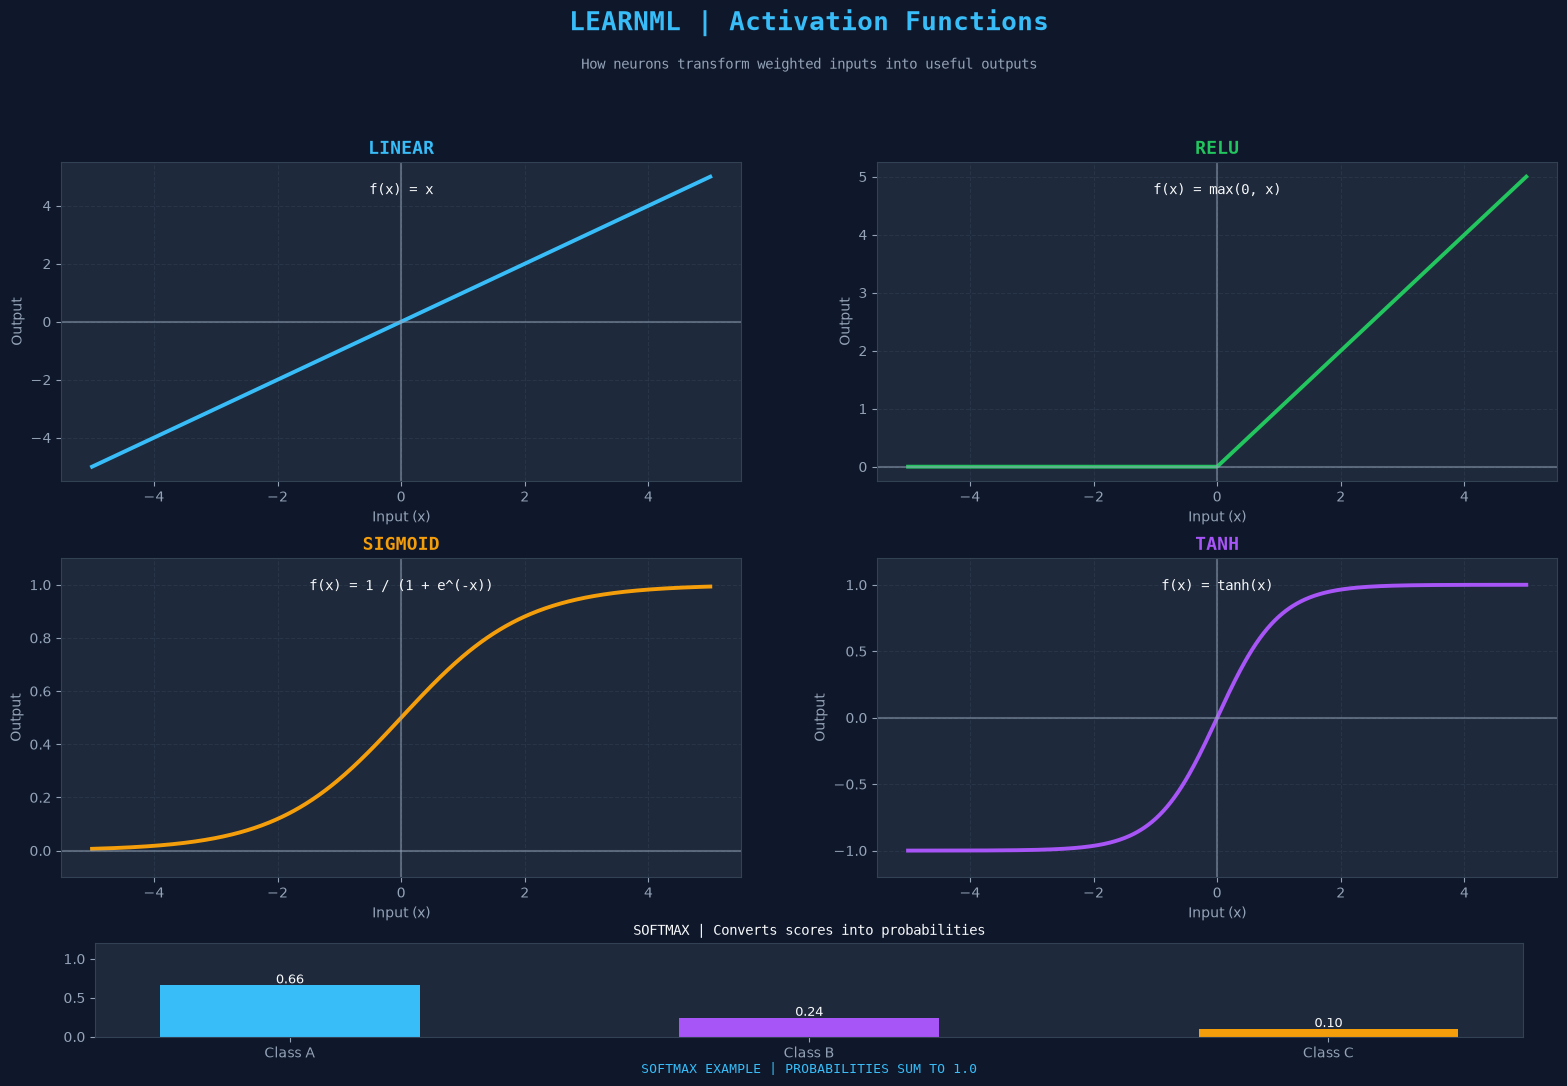

In [22]:
learn_about_activation_functions()


             LEARN ABOUT NN LOSS FUNCTIONS

A loss function measures how far the network's predictions
are from the actual target values.

The goal of training is to minimize this loss.

------------------------------------------------------------
1. MEAN SQUARED ERROR (MSE)
------------------------------------------------------------

Used mainly for regression problems.

    MSE = (1/n) * sum((y_true - y_pred)²)

It calculates the average squared difference between
predictions and actual values.

Example:

    Actual:      [10, 20, 30]
    Predictions: [12, 18, 29]

    MSE = ((10-12)² + (20-18)² + (30-29)²) / 3

        = (4 + 4 + 1) / 3

        = 3

Large errors receive a larger penalty because the
differences are squared.

------------------------------------------------------------
2. BINARY CROSSENTROPY (BCE)
------------------------------------------------------------

Used for binary classification.

The target contains two possible classes:

    0 = Negative
    1 = Positiv

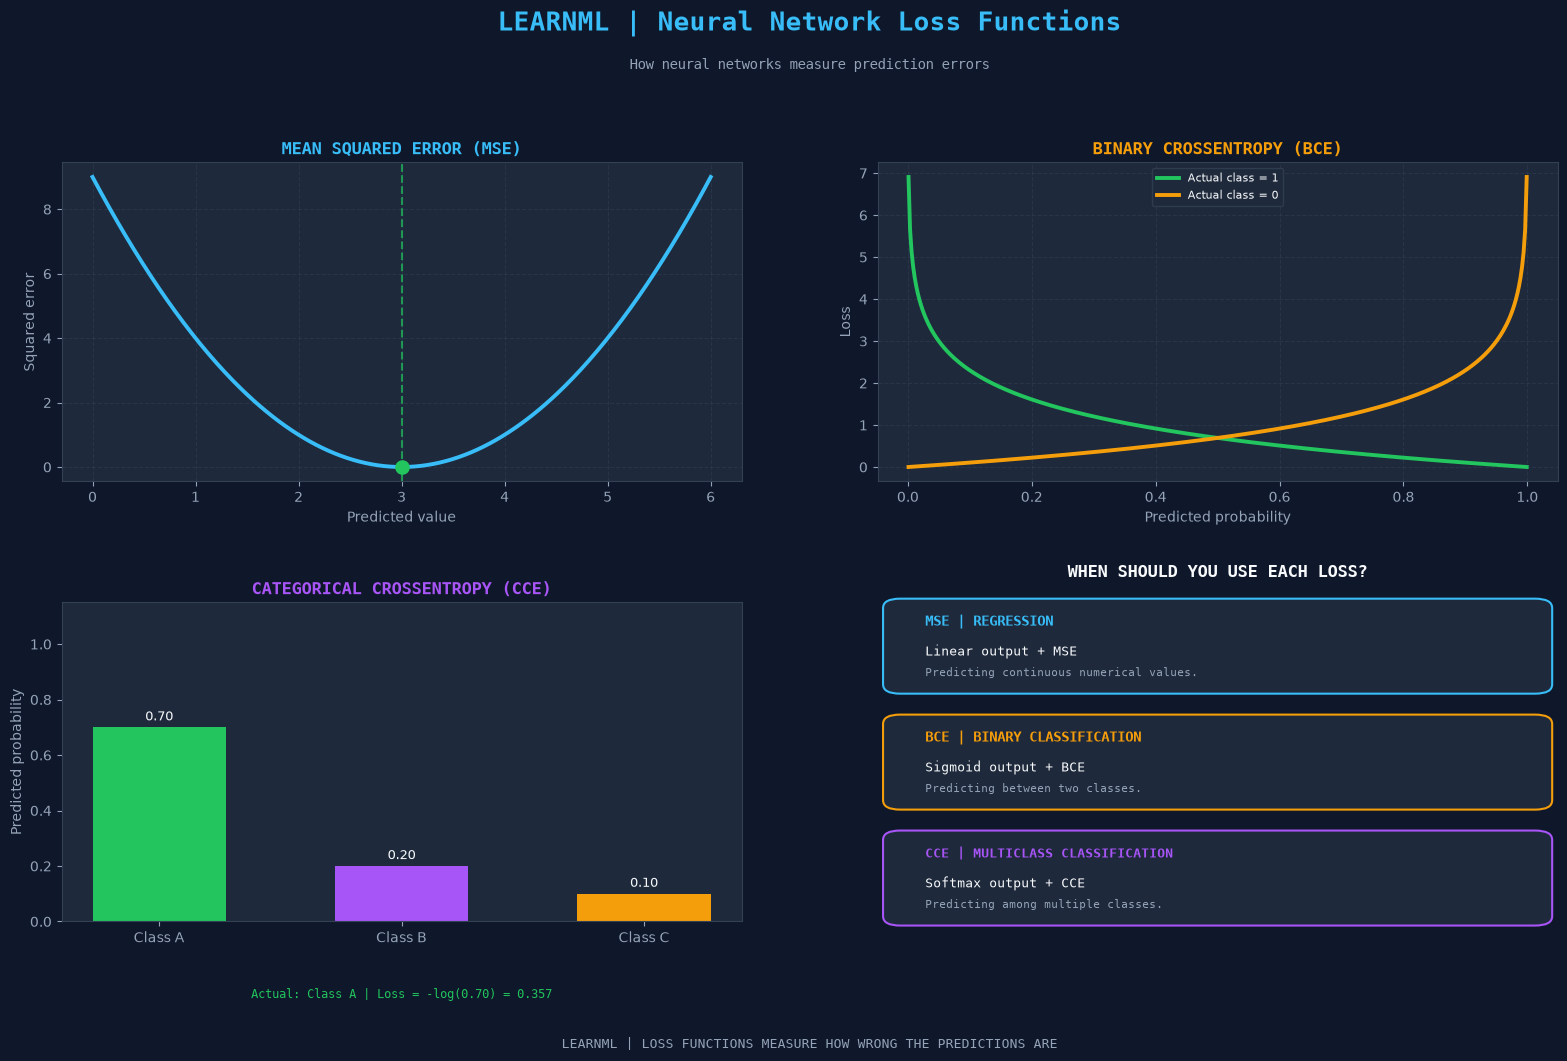

In [23]:
learn_about_nn_loss_functions()


                 LEARN ABOUT OPTIMIZERS

An optimizer is an algorithm responsible for updating the
weights and biases of a neural network during training.

The goal is to minimize the loss function.

TRAINING PROCESS:

1. Forward propagation:
   Calculate predictions using the current weights.

2. Loss calculation:
   Measure the difference between predictions and targets.

3. Backpropagation:
   Calculate gradients with respect to weights and biases.

4. Optimization:
   Use gradients to update the network parameters.

------------------------------------------------------------
1. GRADIENT DESCENT
------------------------------------------------------------

Gradient descent updates parameters in the opposite
direction of the gradient.

    W = W - learning_rate * dW
    b = b - learning_rate * db

Where:

W  = weights
b  = biases
dW = gradient of loss with respect to weights
db = gradient of loss with respect to biases

The learning rate controls the size of each update.

---------

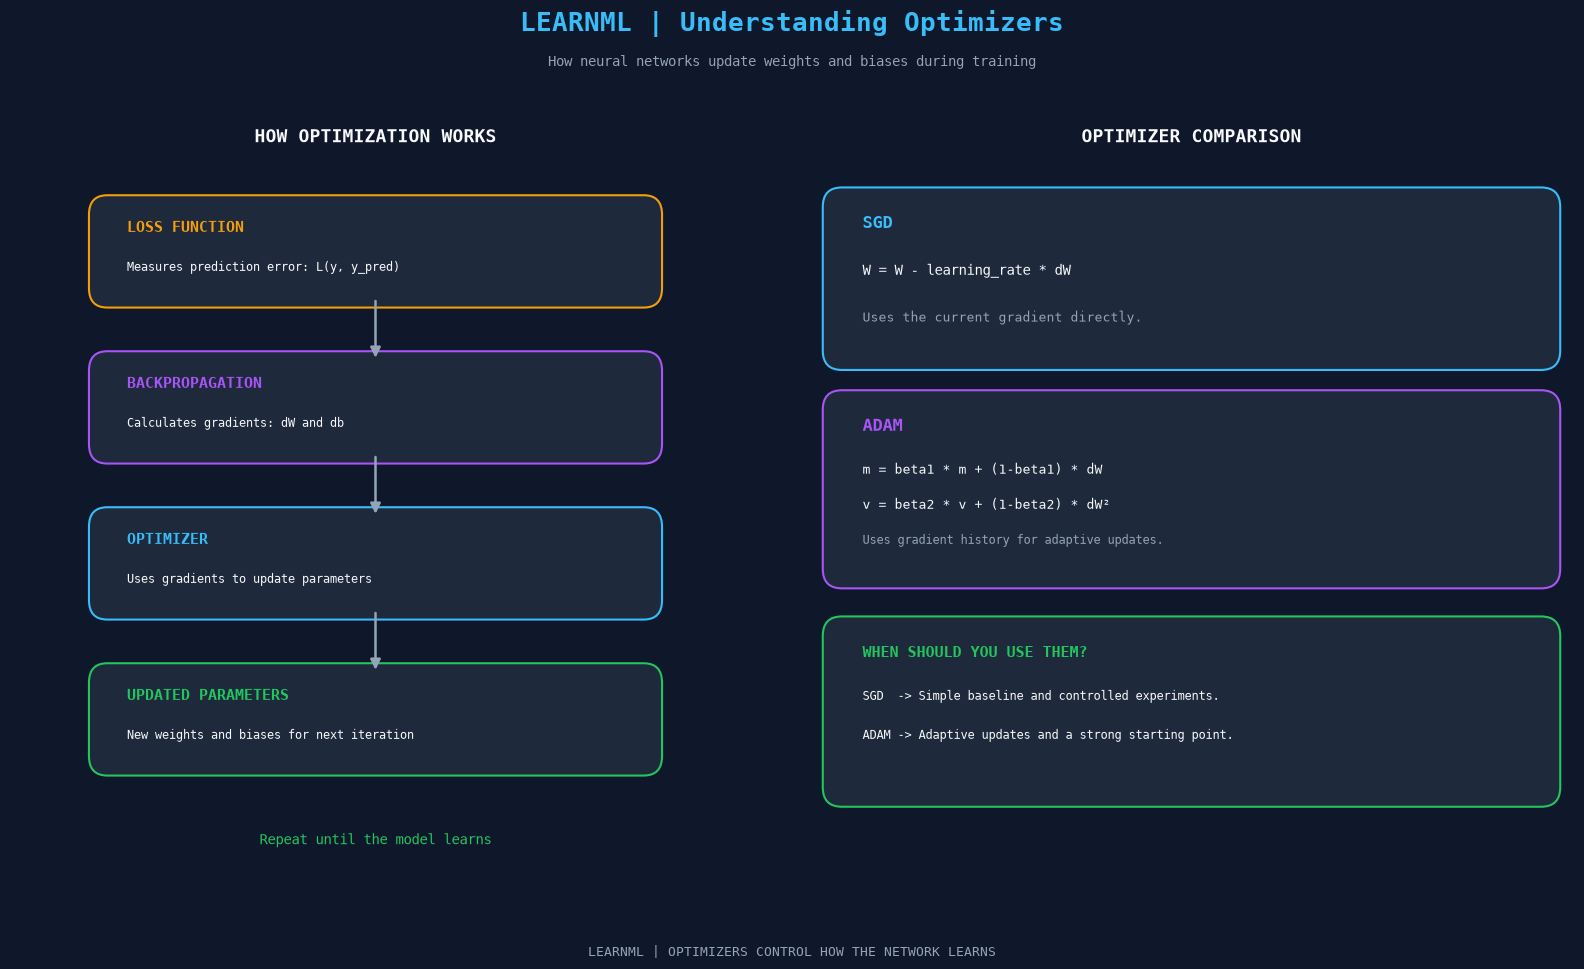

In [24]:
learn_about_optimizers()

LEARNML | ARTIFICIAL NEURAL NETWORKS

A Neural Network is a supervised learning model inspired by the
structure of biological neural networks.

It consists of interconnected layers of neurons. Each neuron receives
inputs, multiplies them by weights, adds a bias, and applies an
activation function.

IMPORTANT CONCEPTS
------------------

1. Network Architecture:
   A neural network consists of an input layer, hidden layers,
   and an output layer.

2. Neurons:
   Each neuron calculates a weighted sum of its inputs and adds a bias.

   z = X @ W + b

   a = activation(z)

3. Weights and Biases:
   Weights determine the importance of connections between neurons.
   Biases allow neurons to shift their activation.

4. Activation Functions:
   Introduce nonlinearity into the network.

   ReLU:    f(x) = max(0, x)
   Sigmoid: f(x) = 1 / (1 + exp(-x))
   Softmax: Converts scores into probabilities.
   Linear:  f(x) = x

5. Forward Propagation:
   Input data travels from the input layer through

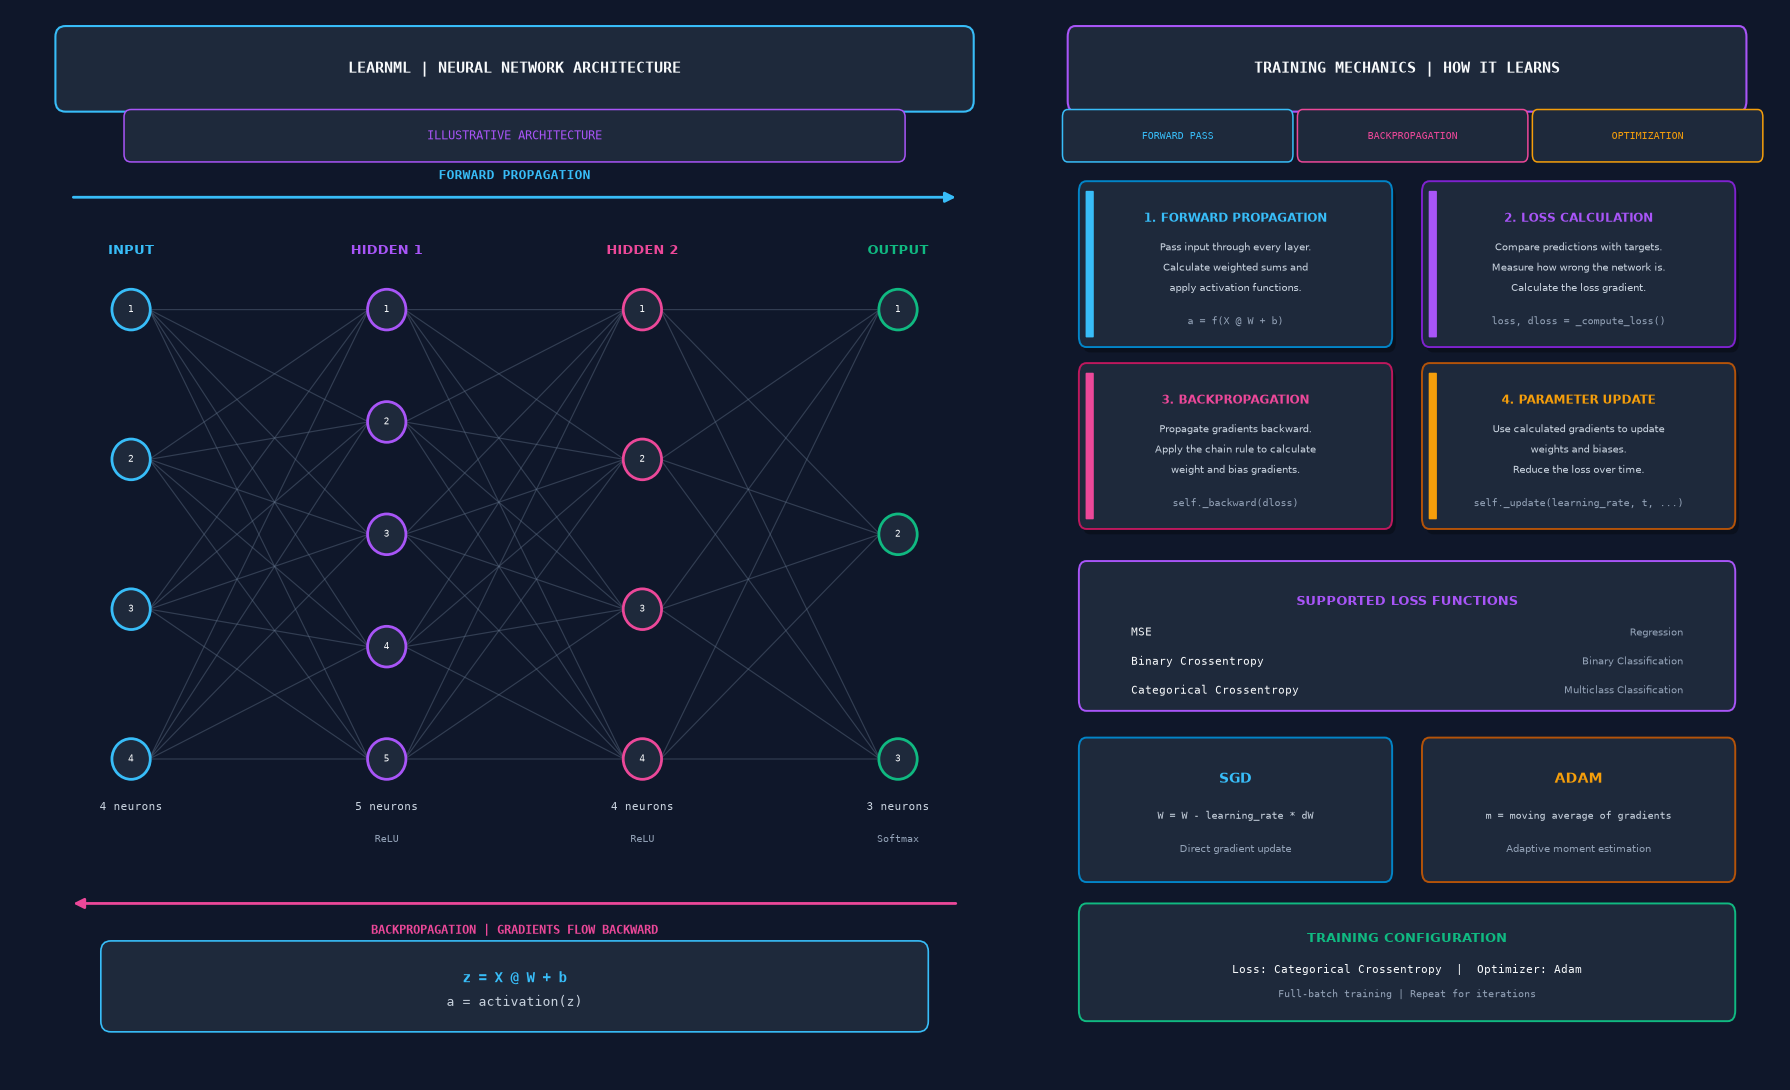

In [25]:
learn_about_NeuralNetwork()

In [39]:
#classification problem
from sklearn.datasets import make_classification
from LearnML.selection.split import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X, y = make_classification(
    n_samples=2000,
    n_features=20,
    n_informative=15,
    n_redundant=5,
    n_classes=4,
    n_clusters_per_class=2,
    class_sep=0.8,
    flip_y=0.05,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

encoder = OneHotEncoder(sparse_output=False)
y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1))

Text(0.5, 1.0, 'Training Data Distribution')

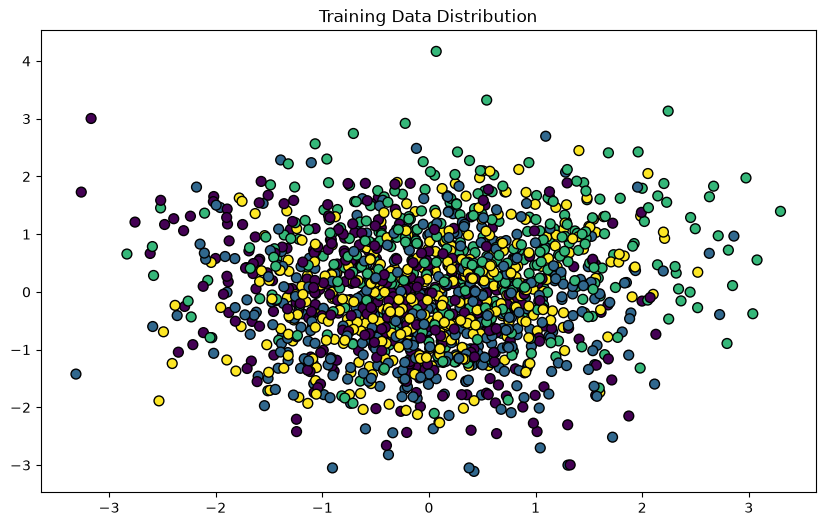

In [40]:
#visualize the data distribution
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k', s=50)
plt.title('Training Data Distribution')     

In [41]:
classification_model = NeuralNetwork([
    Layer(20, 64, activation='relu'),
    Layer(64, 64, activation='relu'),
    Layer(64, 32, activation='relu'),
    Layer(32, 32, activation='relu'),
    Layer(32, 16, activation='relu'),
    Layer(16, 4, activation='softmax'),
])
classification_model.compile(loss='categorical crossentropy', optimizer="adam")


Epoch 1000/1000 [==============================>] - loss: 0.0000


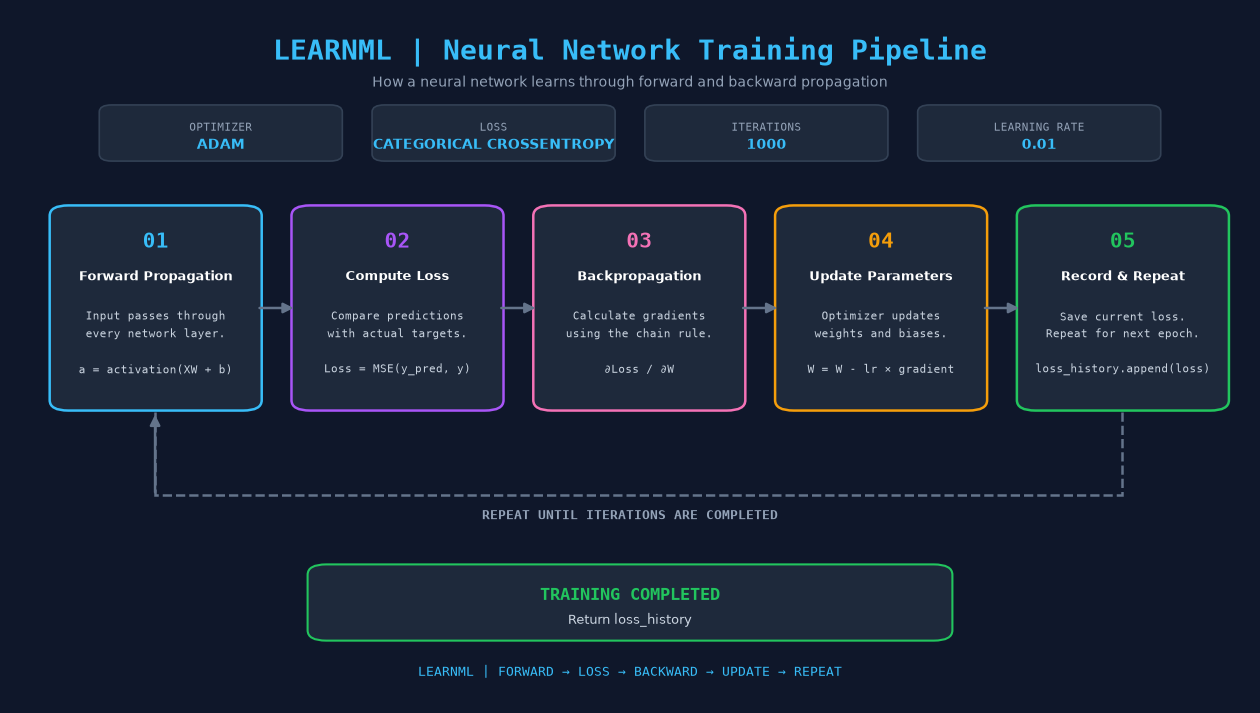

In [42]:
hist=classification_model.fit(X_train, y_train_oh, learning_rate=0.01, iterations=1000, verbose=True)


In [43]:
predicted_labels = classification_model.predict_classes(X_test)

In [54]:
from LearnML.metrics.metrics import classification_report,regression_report
print(classification_report(y_test, predicted_labels))

Accuracy: 0.0016133720930232558
Precision: 1.0
Recall: 0.4472361809045226
F1 Score: 0.6180555555555556
None


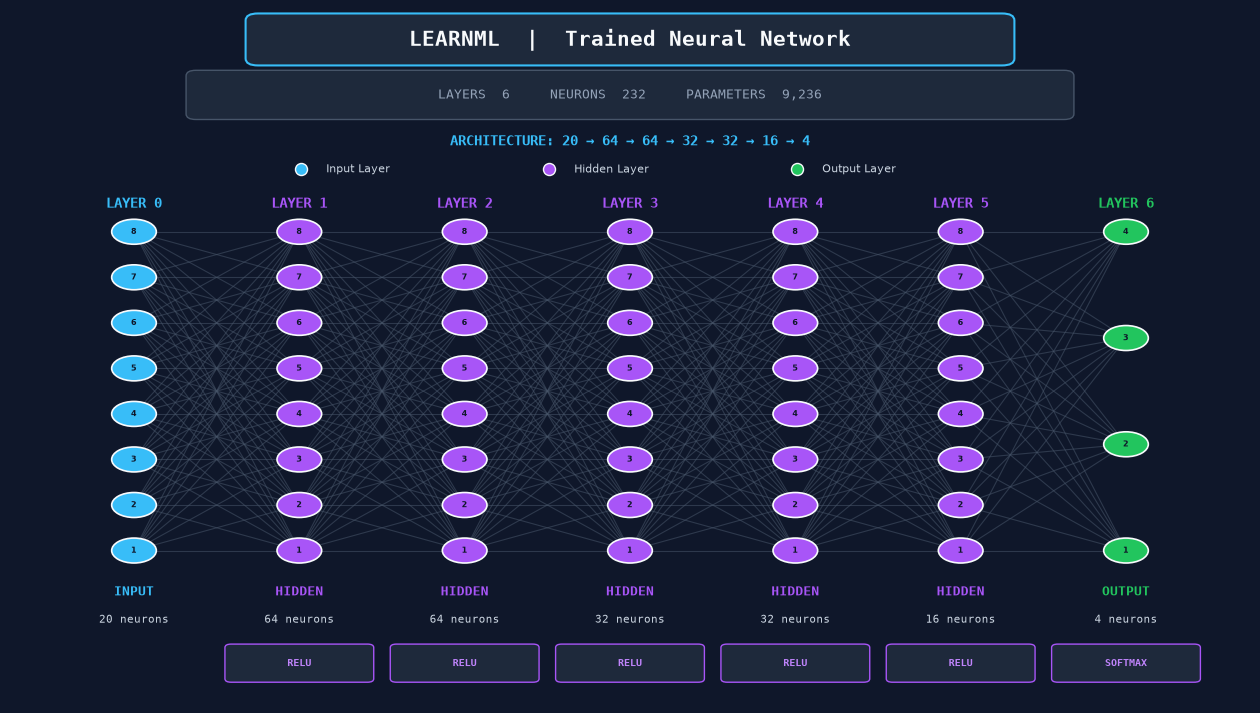

In [45]:
classification_model.visualize()

In [46]:
#regression problem
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler

# Load California Housing dataset
housing = fetch_california_housing()

X = housing.data
y = housing.target.reshape(-1, 1)

print("Features:", X.shape)
print("Target:", y.shape)
print("Feature names:", housing.feature_names)

Features: (20640, 8)
Target: (20640, 1)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Normalize input features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (16512, 8)
Testing: (4128, 8)


In [50]:
regression_model = NeuralNetwork([Layer(8, 64, activation='relu'),
                                 Layer(64, 32, activation='relu'),
                                 Layer(32, 1, activation='linear')])

regression_model.compile(loss='mse')

Epoch 1000/1000 [==============================>] - loss: 0.3020


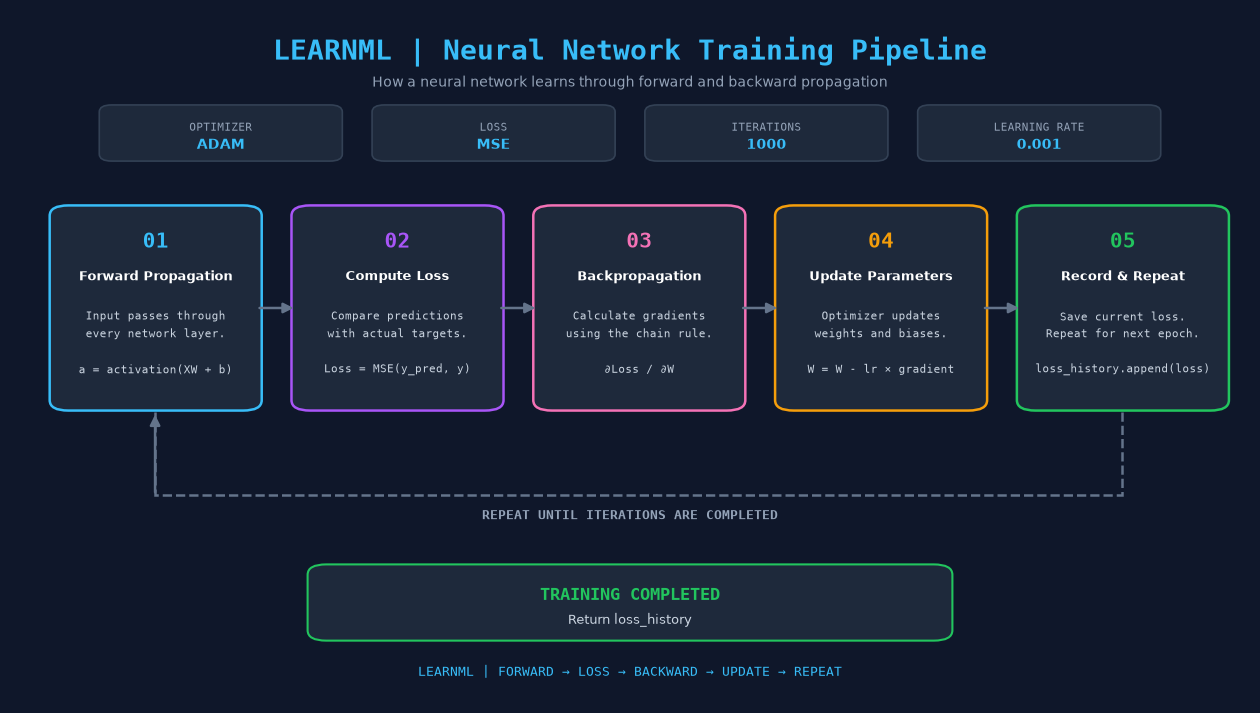

In [53]:
history = regression_model.fit(
    X_train,
    y_train,
    learning_rate=0.001,
    iterations=1000,
    verbose=True
)

In [56]:
predicted_values = regression_model.predict(X_test)
print(regression_report(y_test, predicted_values))

Mean Squared Error: 0.32213830196437715
Root Mean Squared Error: 0.5675722878756301
Mean Absolute Error: 0.3965453333659892
R^2 Score: 0.7518735671708299
None


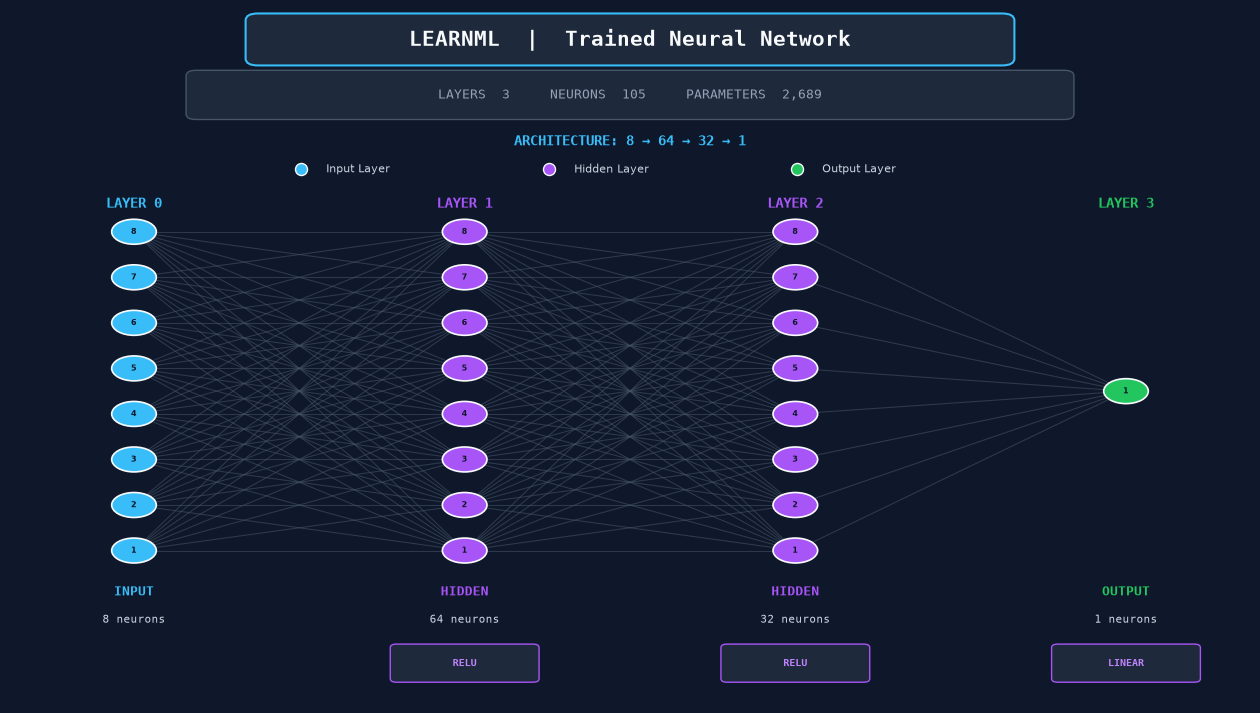

In [57]:
regression_model.visualize()